# Dataset Cleaning for Series Post

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import zscore
from scipy.stats import iqr


teams = pd.read_csv("../basketballPlayoffs/teams.csv")
teams.head()
teamsy11 = pd.read_csv("../basketballPlayoffs/Season_11/teams.csv")

# Concatenate the dataframes row-wise
merged_teams = pd.concat([teams, teamsy11], ignore_index=True)

# Save to a new CSV file
merged_teams.to_csv("../basketballPlayoffs/y11_teams.csv", index=False)

teams = pd.read_csv("../basketballPlayoffs/y11_teams.csv")





# Check For Null Values

In [5]:
null = teams.isnull().values.any()
nan = teams.isna().values.any()

print(null)
print(nan)

# No Missing Values detected so no need of cleaning

True
True


# Dropping Unique Value Columns

In [6]:
for name in teams:
    for col in teams.columns:
        if len(teams[col].unique()) == 1:
            teams.drop(col, inplace=True, axis=1)
    print(f"Processed {name}: Remaining columns: {teams.columns}")


Processed year: Remaining columns: Index(['year', 'tmID', 'franchID', 'confID', 'rank', 'playoff', 'seeded',
       'firstRound', 'semis', 'finals', 'name', 'o_fgm', 'o_fga', 'o_ftm',
       'o_fta', 'o_3pm', 'o_3pa', 'o_oreb', 'o_dreb', 'o_reb', 'o_asts',
       'o_pf', 'o_stl', 'o_to', 'o_blk', 'o_pts', 'd_fgm', 'd_fga', 'd_ftm',
       'd_fta', 'd_3pm', 'd_3pa', 'd_oreb', 'd_dreb', 'd_reb', 'd_asts',
       'd_pf', 'd_stl', 'd_to', 'd_blk', 'd_pts', 'tmORB', 'tmDRB', 'tmTRB',
       'opptmORB', 'opptmDRB', 'opptmTRB', 'won', 'lost', 'GP', 'homeW',
       'homeL', 'awayW', 'awayL', 'confW', 'confL', 'min', 'attend', 'arena'],
      dtype='object')
Processed lgID: Remaining columns: Index(['year', 'tmID', 'franchID', 'confID', 'rank', 'playoff', 'seeded',
       'firstRound', 'semis', 'finals', 'name', 'o_fgm', 'o_fga', 'o_ftm',
       'o_fta', 'o_3pm', 'o_3pa', 'o_oreb', 'o_dreb', 'o_reb', 'o_asts',
       'o_pf', 'o_stl', 'o_to', 'o_blk', 'o_pts', 'd_fgm', 'd_fga', 'd_ftm',
       '

# Dealing with Redundancy

In [7]:

row_count = teams.shape[0]
teams.drop_duplicates(inplace=True)
afterDups_count = teams.shape[0]
rows_deleted = row_count - afterDups_count
print(f"Number of rows deleted: {rows_deleted}")


Number of rows deleted: 0


# Dealing With Outliers

/var/folders/r3/3bq7njsx1kd2kllbx_2c8n6h0000gn/T/ipykernel_3694/4043472881.py:13: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(df[column], fill=True, color='skyblue', alpha=0.5, ax=axes[i])
/var/folders/r3/3bq7njsx1kd2kllbx_2c8n6h0000gn/T/ipykernel_3694/4043472881.py:13: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(df[column], fill=True, color='skyblue', alpha=0.5, ax=axes[i])
/var/folders/r3/3bq7njsx1kd2kllbx_2c8n6h0000gn/T/ipykernel_3694/4043472881.py:13: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(df[column], fill=True, color='skyblue', alpha=0.5, ax=axes[i])
/var/folders/r3/3bq7njsx1kd2kllbx_2c8n6h0000gn/T/ipykernel_3694/4043472881.py:13: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to

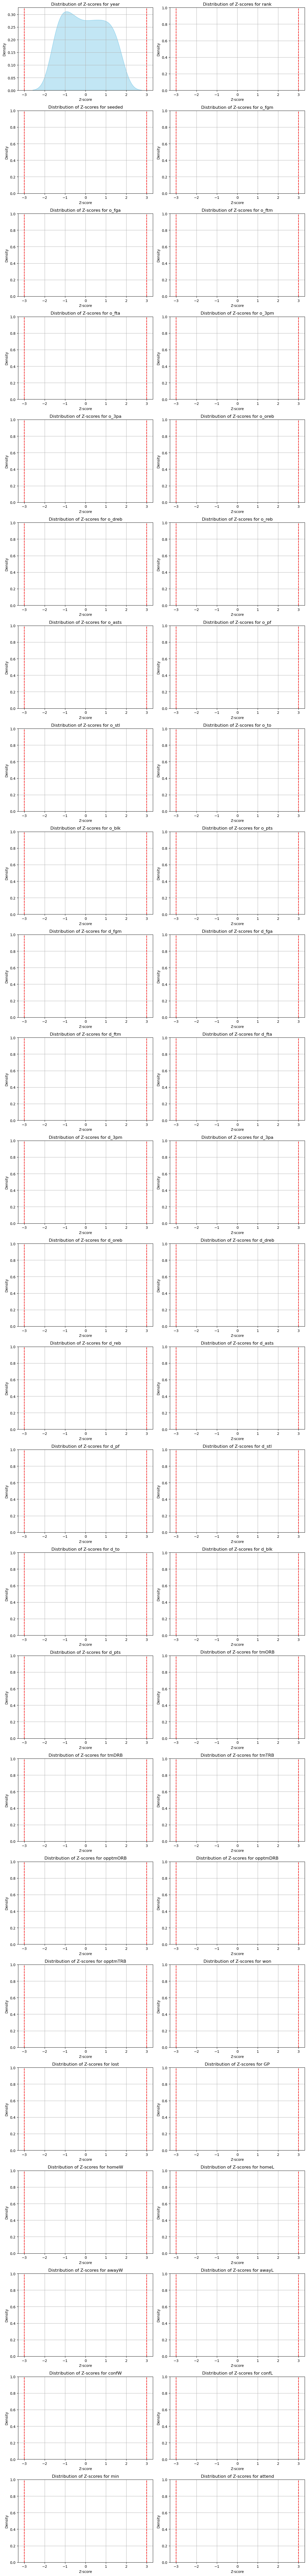

Number of outliers per column:
year        0
rank        0
seeded      0
o_fgm       0
o_fga       0
o_ftm       0
o_fta       0
o_3pm       0
o_3pa       0
o_oreb      0
o_dreb      0
o_reb       0
o_asts      0
o_pf        0
o_stl       0
o_to        0
o_blk       0
o_pts       0
d_fgm       0
d_fga       0
d_ftm       0
d_fta       0
d_3pm       0
d_3pa       0
d_oreb      0
d_dreb      0
d_reb       0
d_asts      0
d_pf        0
d_stl       0
d_to        0
d_blk       0
d_pts       0
tmORB       0
tmDRB       0
tmTRB       0
opptmORB    0
opptmDRB    0
opptmTRB    0
won         0
lost        0
GP          0
homeW       0
homeL       0
awayW       0
awayL       0
confW       0
confL       0
min         0
attend      0
dtype: int64
Rows identified with any outliers (excluding 'attend'): 0
Number of rows deleted: 0


In [8]:


numerical_cols = teams.select_dtypes(['number'])


df = numerical_cols.apply(zscore)


num_columns = 2
num_rows = (len(numerical_cols.columns) + 1) // num_columns  
fig, axes = plt.subplots(num_rows, num_columns, figsize=(12, num_rows * 4))

axes = axes.flatten()
for i, column in enumerate(numerical_cols.columns):
    sns.kdeplot(df[column], fill=True, color='skyblue', alpha=0.5, ax=axes[i])
    axes[i].set_title(f'Distribution of Z-scores for {column}')
    axes[i].set_xlabel('Z-score')
    axes[i].set_ylabel('Density')
    axes[i].grid(True)
    axes[i].axvline(x=3, color='red', linestyle='--')
    axes[i].axvline(x=-3, color='red', linestyle='--')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


threshold = 3
outlier_mask = (df.abs() > threshold)  
outliers_per_column = outlier_mask.sum()
print("Number of outliers per column:")
print(outliers_per_column)


rows_with_outliers = outlier_mask.drop(columns=['attend']).any(axis=1)
print("Rows identified with any outliers (excluding 'attend'):", rows_with_outliers.sum())


df_no_outliers = teams[~(rows_with_outliers)] 


num_rows_deleted = teams.shape[0] - df_no_outliers.shape[0]
print(f"Number of rows deleted: {num_rows_deleted}")


# IQR

Number of outliers per column:
year         0
rank         0
seeded       0
o_fgm        1
o_fga        0
o_ftm        0
o_fta        0
o_3pm        2
o_3pa        2
o_oreb       1
o_dreb       0
o_reb        0
o_asts       1
o_pf         2
o_stl        2
o_to         0
o_blk        1
o_pts        1
d_fgm        1
d_fga        0
d_ftm        2
d_fta        2
d_3pm        2
d_3pa        2
d_oreb       3
d_dreb       0
d_reb        1
d_asts       4
d_pf         0
d_stl        2
d_to         0
d_blk        1
d_pts        1
tmORB        0
tmDRB        0
tmTRB        0
opptmORB     0
opptmDRB     0
opptmTRB     0
won          0
lost         3
GP           0
homeW        1
homeL        3
awayW        4
awayL        5
confW        0
confL        0
min          0
attend      14
dtype: int64
Rows identified with any outliers (excluding 'attend'): 23
Number of rows deleted: 23


/var/folders/r3/3bq7njsx1kd2kllbx_2c8n6h0000gn/T/ipykernel_3694/1994299654.py:31: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(numerical_cols[column], fill=True, color='skyblue', alpha=0.5, ax=axes[i])
/var/folders/r3/3bq7njsx1kd2kllbx_2c8n6h0000gn/T/ipykernel_3694/1994299654.py:31: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(numerical_cols[column], fill=True, color='skyblue', alpha=0.5, ax=axes[i])
/var/folders/r3/3bq7njsx1kd2kllbx_2c8n6h0000gn/T/ipykernel_3694/1994299654.py:31: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(numerical_cols[column], fill=True, color='skyblue', alpha=0.5, ax=axes[i])
/var/folders/r3/3bq7njsx1kd2kllbx_2c8n6h0000gn/T/ipykernel_3694/1994299654.py:31: UserWarning: Dataset has 0 variance; skipping density est

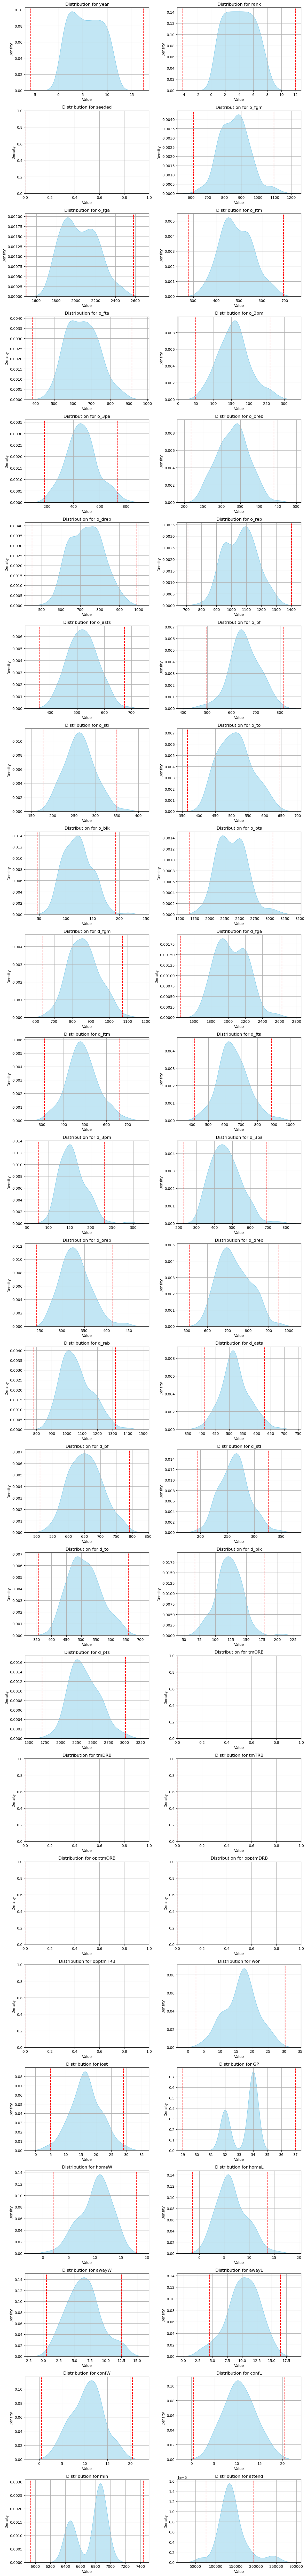

In [9]:
numerical_cols = teams.select_dtypes(['number'])
Q1 = numerical_cols.quantile(0.25)
Q3 = numerical_cols.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (numerical_cols < lower_bound) | (numerical_cols > upper_bound)
outliers_per_column = outlier_mask.sum()
print("Number of outliers per column:")
print(outliers_per_column)


rows_with_outliers = outlier_mask.drop(columns=['attend']).any(axis=1)
print("Rows identified with any outliers (excluding 'attend'):", rows_with_outliers.sum())


df_no_outliers = teams[~(rows_with_outliers)] 
num_rows_deleted = teams.shape[0] - df_no_outliers.shape[0]
print(f"Number of rows deleted: {num_rows_deleted}")


num_columns = 2
num_rows = (len(numerical_cols.columns) + 1) // num_columns  
fig, axes = plt.subplots(num_rows, num_columns, figsize=(12, num_rows * 4))

axes = axes.flatten()
for i, column in enumerate(numerical_cols.columns):
    sns.kdeplot(numerical_cols[column], fill=True, color='skyblue', alpha=0.5, ax=axes[i])
    axes[i].set_title(f'Distribution for {column}')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Density')
    axes[i].grid(True)
    axes[i].axvline(x=lower_bound[column], color='red', linestyle='--')
    axes[i].axvline(x=upper_bound[column], color='red', linestyle='--')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


# Create Clean CSV

In [10]:
teams.to_csv('../cleaned_datasets/teams_cleaned.csv', index=False)